In [ ]:
import matplotlib.pyplot as plt
import sklearn
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix , classification_report, roc_auc_score


In [ ]:
# Needed functions

def read(name):
    return pd.read_csv(f"dataset/{name}.csv", na_values=["\\N"])

def lap_milliseconds(t):
    if pd.isna(t) or ":" not in str(t):
        return np.nan
    minutes, seconds = str(t).split(":")
    return int(minutes) * 60 * 1000 + float(seconds) * 1000

def average_podium_prediction(df, X_test, model):
    """
        Evaluate the model by predicting the podium for each race in the test set, and 
        calculating the average accuracy per race.
    """
    test = df.loc[X_test.index, ["raceId", "podium"]].copy()

    if hasattr(model, "predict_proba"):
        test["score"] = model.predict_proba(X_test)[:, 1]
    else:
        test["score"] = model.decision_function(X_test)      # because svm doesn't have predict_proba

    # keep only the 3 highest-scoring drivers in each race
    test["rank"] = test.groupby("raceId")["score"].rank(method="first", ascending=False)
    top3 = test[test["rank"] <= 3]

    hits = top3.groupby("raceId")["podium"].sum()            # 0 to 3 correct per race
    acc = hits / 3                                           # accuracy per race

    print(f"races evaluated:             {len(hits)}")
    print(f"average accuracy per race:   {acc.mean():.2%}")
    print(f"races with all 3 correct:    {(hits == 3).mean():.2%}")
    print(hits.value_counts().sort_index())                  # how many races got 0, 1, 2, 3


In [177]:
# reading dataset

races = read("races")
results = read("results")
qualifying = read("qualifying")
drivers = read("drivers")
circuits = read("circuits")
constructors_standings = read("constructor_standings")
constructors = read("constructors")
sprints = read("sprint_results")
driver_standings = read("driver_standings")

# we will only choose races from 2014 until present
# because this period is hybrid engines period and much more usable
races = races[races["raceId"] > 899]
results = results[results["raceId"].isin(races["raceId"])]
qualifying = qualifying[qualifying["raceId"].isin(races["raceId"])]
constructors_standings = constructors_standings[constructors_standings["raceId"].isin(races["raceId"])]

# keeping needed columns
races = races[["raceId", "year", "round", "circuitId"]]
results = results[["raceId","driverId","constructorId","grid", "positionOrder"]]
qualifying = qualifying[[ "raceId", "driverId", "constructorId", "q1", "q2", "q3" ]]
constructors_standings = constructors_standings[["raceId", "constructorId", "points", "wins"]]
driver_standings = driver_standings[["raceId", "driverId", "points", "wins"]]
drivers = drivers[["driverId", "forename", "surname"]] 

results = results.rename(columns={"positionOrder": "final_result", "grid": "race_grid"})
sprints = sprints.rename(columns={"positionOrder": "sprint_result", "grid": "sprint_grid"})
sprints = sprints[[ "raceId", "driverId", "constructorId", "sprint_grid", "sprint_result" ]]
driver_standings = driver_standings.rename(columns={"points": "driver_points", "wins": "driver_wins"})
constructors_standings = constructors_standings.rename(columns={"points": "constructor_points", "wins": "constructor_wins"})

In [178]:
# creating a single dataframe with all the needed information

df = (
    races
    .merge(results, on="raceId", how="left")
    .merge(
        qualifying,
        on=["raceId", "driverId", "constructorId"],
        how="left"
    )
    .merge(
        constructors_standings,
        on=["raceId", "constructorId"],
        how="left"
    )
    .merge(
        sprints,
        on=["raceId", "driverId", "constructorId"],
        how="left",
    )
    .merge(
        driver_standings,
        on=["raceId", "driverId"],
        how="left",
    )
    .merge(drivers,
        on="driverId", 
        how="left"
    )
)

# change laptime to milliseconds
df["q1"] = df["q1"].apply(lap_milliseconds)
df["q2"] = df["q2"].apply(lap_milliseconds)
df["q3"] = df["q3"].apply(lap_milliseconds)

# deal with nan or 0
df.dropna(subset=['driverId'], inplace = True)
df.dropna(subset=['constructorId'], inplace = True)
df.dropna(subset=['raceId'], inplace = True)

# race grid of 0 means start in the pit lane, so we will set it to the back of grid, same for nan values
df.loc[df["race_grid"] == 0, "race_grid"] = df["race_grid"].max()
df.loc[df["race_grid"].isna(), "race_grid"] = df["race_grid"].max()

df[["sprint_grid", "sprint_result"]] = df[["sprint_grid", "sprint_result"]].fillna(0)


for c in ["q1", "q2", "q3"]:
    fastest = df.groupby("raceId")[c].transform("min")
    df[c] = (fastest / df[c]).fillna(0)   # pole positon is 1 and others are less than 1, if no time set then 0


df["driverId"] = df["driverId"].astype("int")
df["constructorId"] = df["constructorId"].astype("int")
df["raceId"] = df["raceId"].astype("int")
df["race_grid"] = df["race_grid"].astype("int")
df["sprint_grid"] = df["sprint_grid"].astype("int")
df["sprint_result"] = df["sprint_result"].astype("int")
df["final_result"] = df["final_result"].astype("int")
df["podium"] = (df["final_result"] <= 3).astype("int")


# points up to that point of the season, we will use this as a feature to predict podiums
# wins are also upt to that season
df = df.sort_values(["year", "round"])
g = df.groupby(["driverId", "year"])
df["driver_points"] = g["driver_points"].shift(1).fillna(0).astype(int)
df["driver_wins"] = g["driver_wins"].shift(1).fillna(0).astype(int)

# because we have two driver per constructor we need to delete duplicates of constructorid and then shift 1
teams = df[["raceId", "year", "round", "constructorId", "constructor_points", "constructor_wins"]].drop_duplicates(["raceId", "constructorId"])
teams = teams.sort_values(["year", "round"])
g = teams.groupby(["constructorId", "year"])
teams["constructor_points"] = g["constructor_points"].shift(1).fillna(0).astype(int)
teams["constructor_wins"] = g["constructor_wins"].shift(1).fillna(0).astype(int)
df = df.drop(columns=["constructor_points", "constructor_wins"])
df = df.merge(teams[["raceId", "constructorId", "constructor_points", "constructor_wins"]],
              on=["raceId", "constructorId"], how="left")

# podiums won before show how many podiums the driver has won before that race
df = df.sort_values(["year", "round"])
df["podiums_won_before"] = (
    df.groupby(["driverId", "year"])["podium"].cumsum() - df["podium"]
)

df.head(30)


,raceId,year,round,circuitId,driverId,constructorId,race_grid,final_result,q1,q2,...,sprint_grid,sprint_result,driver_points,driver_wins,forename,surname,podium,constructor_points,constructor_wins,podiums_won_before
0,900,2014,1,1,3,131,3,1,0.980673,1.000000,...,0,0,0,0,Nico,Rosberg,1,0,0,0
1,900,2014,1,1,825,1,4,2,0.998087,0.990479,...,0,0,0,0,Kevin,Magnussen,1,0,0,0
2,900,2014,1,1,18,1,10,3,0.993205,0.979193,...,0,0,0,0,Jenson,Button,1,0,0,0
3,900,2014,1,1,4,6,5,4,0.993292,0.994738,...,0,0,0,0,Fernando,Alonso,0,0,0,0
4,900,2014,1,1,822,3,15,5,0.990983,0.984709,...,0,0,0,0,Valtteri,Bottas,0,0,0,0
5,900,2014,1,1,807,10,7,6,0.966792,0.986552,...,0,0,0,0,Nico,Hülkenberg,0,0,0,0
6,900,2014,1,1,8,6,11,7,0.981999,0.978659,...,0,0,0,0,Kimi,Räikkönen,0,0,0,0
7,900,2014,1,1,818,5,6,8,0.970980,0.984737,...,0,0,0,0,Jean-Éric,Vergne,0,0,0,0
8,900,2014,1,1,826,5,8,9,0.967988,0.980188,...,0,0,0,0,Daniil,Kvyat,0,0,0,0
9,900,2014,1,1,815,10,16,10,0.964245,0.953128,...,0,0,0,0,Sergio,Pérez,0,0,0,0


In [179]:
X = df[["race_grid", "q1", "q2", "q3", "sprint_grid", "sprint_result", "driver_points", "driver_wins", "constructor_points", "constructor_wins", "podiums_won_before"]]
Y = df["podium"]

In [180]:
# we use this method over train_test_split because of average_podium_prediction function, we need to use the whole race to predict the podiums, so we can't split the races in half
train_mask = df["year"] < 2026
X_test = X[~train_mask]
y_test = Y[~train_mask]
X_train = X[train_mask]
y_train = Y[train_mask]


In [181]:
# the best recall i could get for logistic regression was 60% with this model

model = make_pipeline(StandardScaler(), LogisticRegression(C = 0.5 ,penalty='l2', max_iter=1000))

model.fit(X_train, y_train)
yhat = model.predict(X_test)

print("logistic regression: ")
print(confusion_matrix(y_test, yhat, labels=[1,0]))
print(classification_report(y_test, yhat))
print(average_podium_prediction(df, X_test, model))

logistic regression: 
[[ 26  25]
 [  9 314]]
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       323
           1       0.74      0.51      0.60        51

    accuracy                           0.91       374
   macro avg       0.83      0.74      0.78       374
weighted avg       0.90      0.91      0.90       374

races evaluated:             17
average accuracy per race:   62.75%
races with all 3 correct:    23.53%
podium
0    1
1    4
2    8
3    4
Name: count, dtype: int64
None


e:\machine learning\projects\predict-f1-winner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [182]:
model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=0.5, gamma='scale'))
model.fit(X_train, y_train)
yhat = model.predict(X_test)

print("svm:")
print(confusion_matrix(y_test, yhat, labels=[1,0]))
print(classification_report(y_test, yhat))
print(average_podium_prediction(df, X_test, model))

svm:
[[ 25  26]
 [  9 314]]
              precision    recall  f1-score   support

           0       0.92      0.97      0.95       323
           1       0.74      0.49      0.59        51

    accuracy                           0.91       374
   macro avg       0.83      0.73      0.77       374
weighted avg       0.90      0.91      0.90       374

races evaluated:             17
average accuracy per race:   66.67%
races with all 3 correct:    29.41%
podium
0    1
1    3
2    8
3    5
Name: count, dtype: int64
None


xgboost: 
[[ 46   5]
 [ 42 281]]
              precision    recall  f1-score   support

           0       0.98      0.87      0.92       323
           1       0.52      0.90      0.66        51

    accuracy                           0.87       374
   macro avg       0.75      0.89      0.79       374
weighted avg       0.92      0.87      0.89       374

races evaluated:             17
average accuracy per race:   62.75%
races with all 3 correct:    23.53%
podium
1    6
2    7
3    4
Name: count, dtype: int64
None
race_grid             0.402912
podiums_won_before    0.186142
q3                    0.163295
driver_wins           0.044359
driver_points         0.038161
q2                    0.036350
constructor_points    0.035753
q1                    0.026202
constructor_wins      0.025838
sprint_result         0.022800
sprint_grid           0.018187
dtype: float32


<Axes: title={'center': 'XGBoost feature importance'}>

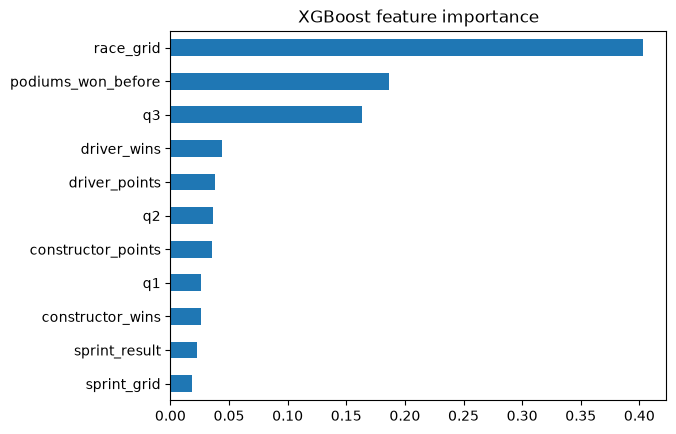

In [183]:
scale_of_classes = (y_train == 0).sum() / (y_train == 1).sum()

model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_of_classes, # we choose to not use it, but if wanted can be used to balance the classes
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)
yhat = model.predict(X_test)

print("xgboost: ")
print(confusion_matrix(y_test, yhat, labels=[1,0]))
print(classification_report(y_test, yhat))
print(average_podium_prediction(df, X_test, model))

importance = pd.Series(model.feature_importances_, index=X_train.columns)
print(importance.sort_values(ascending=False))

importance.sort_values().plot(kind="barh", title="XGBoost feature importance")

In [184]:
model = RandomForestClassifier(
    n_jobs = -1,
    max_depth = 3,
    min_samples_leaf = 3,
    n_estimators = 300,
    class_weight = "balanced",
    random_state=42,
    )
model.fit(X_train, y_train)
yhat = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print("Random Forest:")
print(confusion_matrix(y_test, yhat, labels=[1,0]))
print(classification_report(y_test, yhat))
print("ROC-AUC:", roc_auc_score(y_test, proba))
print(average_podium_prediction(df, X_test, model))


Random Forest:
[[ 48   3]
 [ 56 267]]
              precision    recall  f1-score   support

           0       0.99      0.83      0.90       323
           1       0.46      0.94      0.62        51

    accuracy                           0.84       374
   macro avg       0.73      0.88      0.76       374
weighted avg       0.92      0.84      0.86       374

ROC-AUC: 0.9419656407454623
races evaluated:             17
average accuracy per race:   64.71%
races with all 3 correct:    29.41%
podium
1    6
2    6
3    5
Name: count, dtype: int64
None
